# ЛР-1. Линейные методы бинарной классификации

Цель работы: реализовать Ridge в матричной форме и линейный классификатор с градиентным спуском, сравнить их качество и исследовать влияние регуляризации.

[Исходное условие](https://docs.google.com/document/d/1W10esDhvHeBwJhE9zPIHYhnCB0SM9jwMNd_NIcft4oY/edit).

Работа включает подготовку данных, вывод градиентов, подбор параметров, кривые обучения и пути коэффициентов по L1 и L2. Классификаторы реализованы самостоятельно. Scikit-learn используется для набора данных, разбиений и метрик.

## 1. Данные и воспроизводимость

Используется Breast Cancer Wisconsin Diagnostic: 569 объектов и 30 числовых признаков, вычисленных по изображениям клеточных ядер. Исходные классы: malignant (злокачественный) и benign (доброкачественный). Здесь $y=+1$ соответствует malignant, $y=-1$ соответствует benign.

[Описание набора в scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html), [первичный источник UCI](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic). Все 30 признаков сохраняются: их число невелико для матричного решения. Пропусков нет, категориальное кодирование не требуется.

Целевая метрика $\mathrm{accuracy}=\frac1n\sum_i [\hat y_i=y_i]$ измеряет долю верных ответов. Для задачи сравнения алгоритмов она проста и интерпретируема; сама по себе она не оценивает отдельно ошибки по злокачественному классу. Это учебный эксперимент с фиксированным набором данных.

Финальная тестовая часть содержит 20% объектов. Разбиение стратифицированное, seed = 42. Для каждого признака $j$ вычисляем $z_{ij}=(x_{ij}-\mu_j)/s_j$, где среднее и стандартное отклонение берутся только из тренировочной части. Используется стандартное отклонение с делителем $n$. На фолдах CV и повторных разбиениях преобразование обучается заново.

In [1]:
import os
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['VECLIB_MAXIMUM_THREADS'] = '1'
from pathlib import Path
from itertools import product
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from scipy.stats import t
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix
from IPython.display import display, Markdown

SEED = 42
N_ITER = 2000
ROOT = Path.cwd()
(ROOT / 'figures').mkdir(exist_ok=True)
(ROOT / 'results').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 11, 'axes.grid': True,
                     'grid.alpha': 0.25, 'figure.dpi': 110})
np.set_printoptions(precision=5, suppress=True)

In [2]:
if not (ROOT / 'data.csv').exists():
    dataset = load_breast_cancer()
    data = pd.DataFrame(dataset.data, columns=dataset.feature_names)
    data['target'] = np.where(dataset.target == 0, 1, -1)
    data['class_name'] = np.where(data['target'] == 1, 'malignant', 'benign')
    data.to_csv(ROOT / 'data.csv', index=False)
data = pd.read_csv(ROOT / 'data.csv')
feature_names = data.columns.drop(['target', 'class_name']).tolist()
X = data[feature_names].to_numpy(dtype=float)
y = data['target'].to_numpy(dtype=int)
assert X.shape == (569, 30)
assert not data.isna().any().any()
assert set(y) == {-1, 1}
assert (data['class_name'] == np.where(y == 1, 'malignant', 'benign')).all()
train_idx, final_idx = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED)
X_train_raw, X_final_raw = X[train_idx], X[final_idx]
y_train, y_final = y[train_idx], y[final_idx]
display(pd.DataFrame({'часть': ['все данные', 'тренировочная', 'финальная тестовая'],
                      'объектов': [len(y), len(y_train), len(y_final)],
                      'malignant (+1)': [(a == 1).sum() for a in [y, y_train, y_final]],
                      'benign (-1)': [(a == -1).sum() for a in [y, y_train, y_final]]}))
display(data.head(3))

,часть,объектов,malignant (+1),benign (-1)
0,все данные,569,212,357
1,тренировочная,455,170,285
2,финальная тестовая,114,42,72


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,class_name
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1,malignant
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1,malignant
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1,malignant


## 2. Модели и аналитические градиенты

Пусть $X\in\mathbb R^{n\times d}$ содержит стандартизованные признаки, $w\in\mathbb R^d$ содержит коэффициенты, $b$ задаёт свободный член. Решающее значение $f_i=x_i^Tw+b$. Предсказываем $+1$ при $f_i\ge0$, иначе $-1$. Отступ $m_i=y_i f_i$ положителен при верной классификации.

### Ridge

Добавим столбец единиц: $A=[X,\mathbf1]$, $\theta=(w,b)$. Минимизируем

$$J_R(\theta)=\frac{1}{2n}\|A\theta-y\|_2^2+\frac\lambda2\|w\|_2^2.$$

Приравнивание градиента к нулю даёт

$$\left(\frac{A^TA}{n}+\lambda D\right)\theta=\frac{A^Ty}{n},\quad D=\mathrm{diag}(1,\ldots,1,0).$$

Последний ноль исключает свободный член из штрафа. Используем `numpy.linalg.solve`: явное обращение матрицы не требуется. Ridge аппроксимирует числовые метки $\pm1$, а порог ноль превращает результат в классификацию.

### Три риска для градиентного классификатора

| Риск | $\ell(m)$ | Производная по отступу $\ell'(m)$ |
|:---|:---|:---|
| Логистический | $\log(1+e^{-m})$ | $-1/(1+e^m)$ |
| Экспоненциальный | $e^{-m}$ | $-e^{-m}$ |
| Квадратичный hinge | $\max(0,1-m)^2$ | $-2\max(0,1-m)$ |

У квадратичного hinge производная в $m=1$ равна нулю с обеих сторон. Для логистического риска применяются устойчивые `logaddexp` и `expit`. Экспоненциальная потеря не обрезается: нечисловые значения останавливают расчёт.

Эмпирический риск $R=\frac1n\sum_i\ell(m_i)$. Целевая функция с Elastic Net:

$$J(w,b)=R(w,b)+\lambda_1\sum_j|w_j|+\frac{\lambda_2}{2}\sum_jw_j^2.$$

По правилу цепочки:

$$\nabla_w J=\frac1n X^T\bigl(y\odot\ell'(m)\bigr)+\lambda_1\operatorname{sign}(w)+\lambda_2w,$$
$$\frac{\partial J}{\partial b}=\frac1n\sum_i y_i\ell'(m_i).$$

Производная гладкой части существует везде. Для $|w_j|$ в нуле производная не существует; допустимые субградиенты лежат в $[-1,1]$. Выбираем $\operatorname{sign}(0)=0$. Поэтому при $\lambda_1>0$ используется субградиентный вариант спуска. Обновление $\theta_{k+1}=\theta_k-\eta_k g_k$ вычисляет градиент по всем тренировочным объектам. Начальный вектор нулевой. В подборе параметров скорость постоянна. Численный способ для путей коэффициентов описан в разделе 5.

In [3]:
def standardize(X_train, X_test):
    mean = X_train.mean(axis=0)
    std = X_train.std(axis=0)
    return (X_train - mean) / std, (X_test - mean) / std, mean, std


def predict(X, theta):
    return np.where(X @ theta[:-1] + theta[-1] >= 0, 1, -1)


def ridge_fit(X, y, l2):
    A = np.column_stack([X, np.ones(len(X))])
    penalty = np.diag([l2] * X.shape[1] + [0])
    return np.linalg.solve(A.T @ A / len(X) + penalty, A.T @ y / len(X))


def loss_and_derivative(margin, loss):
    if loss == 'logistic':
        return np.logaddexp(0, -margin), -expit(-margin)
    if loss == 'exponential':
        values = np.exp(-margin)
        return values, -values
    if loss == 'squared_hinge':
        shortfall = np.maximum(0, 1 - margin)
        return shortfall ** 2, -2 * shortfall
    raise ValueError(loss)


def objective_gradient(X, y, theta, loss, l1, l2):
    margin = y * (X @ theta[:-1] + theta[-1])
    values, derivative = loss_and_derivative(margin, loss)
    weighted = derivative * y
    gradient = np.r_[X.T @ weighted / len(X), weighted.mean()]
    gradient[:-1] += l1 * np.sign(theta[:-1]) + l2 * theta[:-1]
    objective = values.mean() + l1 * np.abs(theta[:-1]).sum() + l2 * (theta[:-1] @ theta[:-1]) / 2
    return float(objective), gradient


def gd_fit(X, y, loss, l1, l2, learning_rate, n_iter, X_test=None, y_test=None,
           record_every=20, decay=False, initial=None):
    theta = np.zeros(X.shape[1] + 1) if initial is None else initial.copy()
    records = []
    for iteration in range(n_iter + 1):
        objective, gradient = objective_gradient(X, y, theta, loss, l1, l2)
        if iteration % record_every == 0 or iteration == n_iter:
            risk = loss_and_derivative(y * (X @ theta[:-1] + theta[-1]), loss)[0].mean()
            row = {'iteration': iteration, 'risk': risk, 'objective': objective,
                   'gradient_norm': np.linalg.norm(gradient)}
            if X_test is not None:
                row['test_accuracy'] = accuracy_score(y_test, predict(X_test, theta))
            records.append(row)
        if not np.isfinite(objective) or not np.isfinite(gradient).all():
            raise FloatingPointError('Нечисловое значение при обучении')
        if iteration == n_iter:
            break
        rate = learning_rate / np.sqrt(1 + iteration / 1000) if decay else learning_rate
        theta -= rate * gradient
    return theta, pd.DataFrame(records)

In [4]:
X_train, X_final, mean_train, std_train = standardize(X_train_raw, X_final_raw)
assert np.allclose(X_train.mean(axis=0), 0, atol=1e-12)
assert np.allclose(X_train.std(axis=0), 1, atol=1e-12)
assert set(train_idx).isdisjoint(final_idx)
print('Стандартизация и разделение данных проверены.')

Стандартизация и разделение данных проверены.


### Проверки математики

Центральная конечная разность $(J(\theta+\varepsilon e_j)-J(\theta-\varepsilon e_j))/(2\varepsilon)$ сравнивается с аналитическим градиентом при $\varepsilon=10^{-6}$. Для L1 берём ненулевые координаты, чтобы не проверять производную в точке излома. Проверяем три риска, оба штрафа и их сочетание; допустимая максимальная абсолютная ошибка $10^{-5}$.

Дополнительно проверяем относительную невязку системы Ridge, исключение свободного члена из регуляризации, правило порога ноль, тренировочные статистики стандартизации и обучение на простой разделимой выборке. Эти проверки были записаны до реализации алгоритмов.

In [5]:
import numpy as np

def run_checks():
    rng = np.random.default_rng(17)
    X = rng.normal(size=(13, 4))
    y = np.where(rng.normal(size=13) >= 0, 1, -1)
    theta = np.array([0.21, -0.32, 0.43, -0.54, 0.16])
    eps = 1e-6
    errors = []
    for loss in ['logistic', 'exponential', 'squared_hinge']:
        for l1, l2 in [(0, 0), (0, 0.13), (0.07, 0), (0.07, 0.13)]:
            value, analytical = objective_gradient(X, y, theta, loss, l1, l2)
            numerical = np.empty_like(theta)
            for j in range(theta.size):
                delta = np.zeros_like(theta)
                delta[j] = eps
                plus = objective_gradient(X, y, theta + delta, loss, l1, l2)[0]
                minus = objective_gradient(X, y, theta - delta, loss, l1, l2)[0]
                numerical[j] = (plus - minus) / (2 * eps)
            error = float(np.max(np.abs(analytical - numerical)))
            assert error < 1e-5, (loss, l1, l2, error)
            errors.append(error)
        _, base = objective_gradient(X, y, theta, loss, 0, 0)
        _, penalized = objective_gradient(X, y, theta, loss, 0.07, 0.13)
        assert base[-1] == penalized[-1]
        assert np.allclose(penalized[:-1] - base[:-1], 0.07 * np.sign(theta[:-1]) + 0.13 * theta[:-1])
    margins = np.array([-1.4, 0.2, 1.7])
    losses, _ = loss_and_derivative(margins, 'squared_hinge')
    assert np.allclose(losses, [5.76, 0.64, 0])
    ridge = ridge_fit(X, y, 0.13)
    A = np.column_stack([X, np.ones(len(X))])
    penalty = np.diag([0.13] * X.shape[1] + [0])
    lhs = A.T @ A / len(X) + penalty
    rhs = A.T @ y / len(X)
    residual = np.linalg.norm(lhs @ ridge - rhs) / np.linalg.norm(rhs)
    assert residual < 1e-10
    assert predict(np.zeros((1, 4)), np.zeros(5))[0] == 1
    X_scaled, test_scaled, mean, std = standardize(X, X + 100)
    assert np.allclose(X_scaled.mean(axis=0), 0, atol=1e-12)
    assert np.allclose(X_scaled.std(axis=0), 1, atol=1e-12)
    assert np.allclose(test_scaled, (X + 100 - mean) / std)
    small_X = np.array([[-2.], [-1.], [1.], [2.]])
    small_y = np.array([-1, -1, 1, 1])
    for loss in ['logistic', 'exponential', 'squared_hinge']:
        fitted, history = gd_fit(small_X, small_y, loss, 0, 0, 0.01, 300, small_X, small_y, 37)
        assert np.array_equal(predict(small_X, fitted), small_y)
        assert history['iteration'].iloc[0] == 0
        assert history['iteration'].iloc[-1] == 300
        assert history['risk'].iloc[-1] < history['risk'].iloc[0]
        assert np.isfinite(history.select_dtypes('number').to_numpy()).all()
    return {'max_gradient_error': max(errors), 'ridge_relative_residual': residual, 'checks': 'passed'}


verification = run_checks()
display(verification)

{'max_gradient_error': 1.4928444591610912e-10,
 'ridge_relative_residual': np.float64(8.131526062823811e-17),
 'checks': 'passed'}

## 3. Подбор гиперпараметров

На 455 тренировочных объектах выполняется стратифицированная 5-fold CV с seed = 42. Каждый фолд имеет собственные $\mu$ и $s$. Финальные 114 тестовых объектов не передаются в подбор.

Сетка Ridge: 8 логарифмических значений $\lambda\in[10^{-5},10^2]$. Сетка градиентного метода: три риска, скорости $0.001,0.005,0.01$ и пары $(\lambda_1,\lambda_2)$: $(0,0)$, $(0.001,0)$, $(0,0.001)$, $(0.001,0.001)$, $(0.01,0.01)$. Всего 45 конфигураций, по 2000 итераций каждая.

Выбирается максимальная средняя accuracy по фолдам. При точном равенстве сохраняется первая конфигурация: порядок рисков logistic, exponential, squared_hinge; затем скорости по возрастанию; затем пары в указанном порядке. Для Ridge коэффициенты идут по возрастанию. Разброс по фолдам приводится как стандартное отклонение с делителем $K-1$.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = []
for fit_idx, valid_idx in cv.split(X_train_raw, y_train):
    fit_X, valid_X, _, _ = standardize(X_train_raw[fit_idx], X_train_raw[valid_idx])
    folds.append((fit_X, y_train[fit_idx], valid_X, y_train[valid_idx]))
ridge_rows = []
for l2 in np.logspace(-5, 2, 8):
    scores = [accuracy_score(vy, predict(vX, ridge_fit(fX, fy, l2))) for fX, fy, vX, vy in folds]
    ridge_rows.append({'l2': l2, 'mean_accuracy': np.mean(scores), 'std_accuracy': np.std(scores, ddof=1),
                       **{f'fold_{i + 1}': s for i, s in enumerate(scores)}})
ridge_cv = pd.DataFrame(ridge_rows)
pairs = [(0, 0), (0.001, 0), (0, 0.001), (0.001, 0.001), (0.01, 0.01)]
gd_rows = []
for loss, rate, pair in product(['logistic', 'exponential', 'squared_hinge'], [0.001, 0.005, 0.01], pairs):
    l1, l2 = pair
    scores = []
    for fX, fy, vX, vy in folds:
        fitted, history = gd_fit(fX, fy, loss, l1, l2, rate, N_ITER, record_every=N_ITER)
        scores.append(accuracy_score(vy, predict(vX, fitted)))
    gd_rows.append({'loss': loss, 'learning_rate': rate, 'l1': l1, 'l2': l2,
                    'mean_accuracy': np.mean(scores), 'std_accuracy': np.std(scores, ddof=1),
                    **{f'fold_{i + 1}': s for i, s in enumerate(scores)}})
ridge_cv.to_csv(ROOT / 'results/ridge_cv.csv', index=False)
gd_cv = pd.DataFrame(gd_rows)
gd_cv.to_csv(ROOT / 'results/gd_cv.csv', index=False)
best_ridge = ridge_cv.loc[ridge_cv['mean_accuracy'].idxmax()]
best_gd = gd_cv.loc[gd_cv['mean_accuracy'].idxmax()]
params = {'loss': best_gd['loss'], 'l1': float(best_gd['l1']), 'l2': float(best_gd['l2']),
          'learning_rate': float(best_gd['learning_rate']), 'n_iter': N_ITER}
display(ridge_cv[['l2', 'mean_accuracy', 'std_accuracy']])
display(gd_cv.sort_values('mean_accuracy', ascending=False, kind='stable').head(10))
display(pd.DataFrame([best_gd[['loss', 'learning_rate', 'l1', 'l2', 'mean_accuracy', 'std_accuracy']]]))

,l2,mean_accuracy,std_accuracy
0,0.00001,0.956044,0.025772
1,0.00010,0.956044,0.020559
2,0.00100,0.958242,0.023824
3,0.01000,0.956044,0.025772
4,0.10000,0.958242,0.018057
5,1.00000,0.947253,0.023824
6,10.00000,0.894505,0.039315
7,100.00000,0.643956,0.014743


,loss,learning_rate,l1,l2,mean_accuracy,std_accuracy,fold_1,fold_2,fold_3,fold_4,fold_5
5,logistic,0.005,0.000,0.000,0.978022,0.007770,0.967033,0.978022,0.978022,0.978022,0.989011
6,logistic,0.005,0.001,0.000,0.978022,0.007770,0.967033,0.978022,0.978022,0.978022,0.989011
7,logistic,0.005,0.000,0.001,0.978022,0.007770,0.967033,0.978022,0.978022,0.978022,0.989011
8,logistic,0.005,0.001,0.001,0.978022,0.007770,0.967033,0.978022,0.978022,0.978022,0.989011
25,exponential,0.010,0.000,0.000,0.975824,0.019658,0.945055,0.978022,1.000000,0.978022,0.978022
26,exponential,0.010,0.001,0.000,0.975824,0.019658,0.945055,0.978022,1.000000,0.978022,0.978022
27,exponential,0.010,0.000,0.001,0.975824,0.019658,0.945055,0.978022,1.000000,0.978022,0.978022
28,exponential,0.010,0.001,0.001,0.975824,0.019658,0.945055,0.978022,1.000000,0.978022,0.978022
14,logistic,0.010,0.010,0.010,0.973626,0.016666,0.945055,0.978022,0.978022,0.978022,0.989011
34,squared_hinge,0.001,0.010,0.010,0.973626,0.012529,0.956044,0.967033,0.978022,0.978022,0.989011


,loss,learning_rate,l1,l2,mean_accuracy,std_accuracy
5,logistic,0.005,0.0,0.0,0.978022,0.00777


In [7]:
ridge_theta = ridge_fit(X_train, y_train, float(best_ridge['l2']))
gd_theta, train_history = gd_fit(X_train, y_train, **params)
final_rows = []
for name, fitted, cv_accuracy in [('Ridge', ridge_theta, best_ridge['mean_accuracy']),
                                  ('Градиентный классификатор', gd_theta, best_gd['mean_accuracy'])]:
    prediction = predict(X_final, fitted)
    final_rows.append({'model': name, 'cv_accuracy': float(cv_accuracy),
                       'test_accuracy': accuracy_score(y_final, prediction),
                       'correct': int((prediction == y_final).sum()), 'total': len(y_final)})
final_results = pd.DataFrame(final_rows)
final_results.to_csv(ROOT / 'results/final_metrics.csv', index=False)
train_history.to_csv(ROOT / 'results/train_history.csv', index=False)
display(final_results)
for name, fitted in [('Ridge', ridge_theta), ('Градиентный классификатор', gd_theta)]:
    matrix = confusion_matrix(y_final, predict(X_final, fitted), labels=[1, -1])
    print(name)
    display(pd.DataFrame(matrix, index=['истина malignant', 'истина benign'],
                        columns=['прогноз malignant', 'прогноз benign']))

,model,cv_accuracy,test_accuracy,correct,total
0,Ridge,0.958242,0.956140,109,114
1,Градиентный классификатор,0.978022,0.982456,112,114


Ridge


,прогноз malignant,прогноз benign
истина malignant,37,5
истина benign,0,72


Градиентный классификатор


,прогноз malignant,прогноз benign
истина malignant,40,2
истина benign,0,72


## 4. Кривые обучения

### Риск на тренировочной части

Показываем $R_k$, без штрафов регуляризации, на каждой двадцатой итерации и на последней. Сглаживаем записанные точки экспоненциальным средним: $S_0=R_0$, $S_j=0.1R_j+0.9S_{j-1}$. Индекс $j$ обозначает номер записанной точки, а ось графика содержит итерации спуска. Сглаживание запаздывает относительно исходного риска и служит только для отображения.

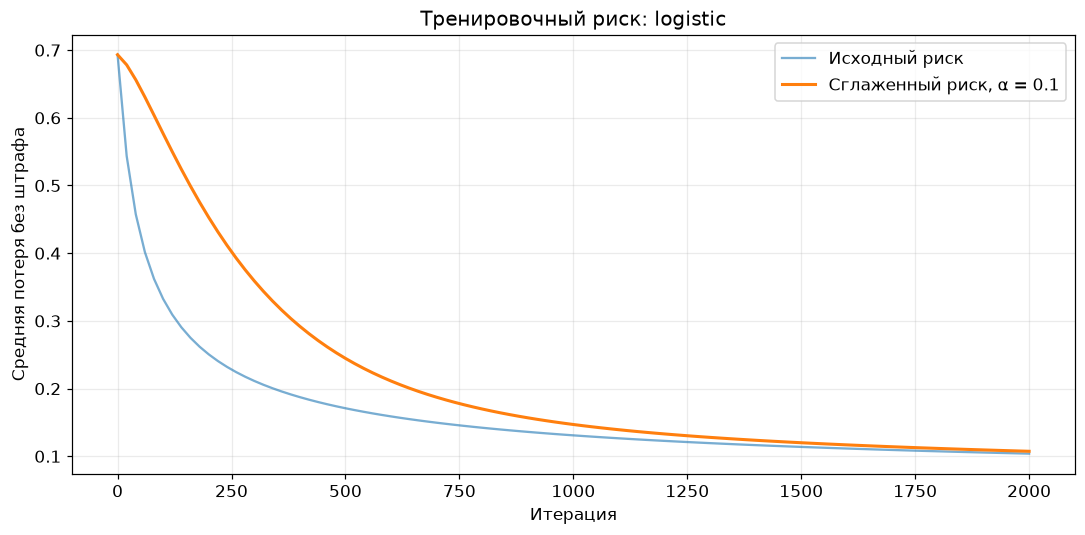

In [8]:
smooth_risk = train_history['risk'].ewm(alpha=0.1, adjust=False).mean()
fig, ax = plt.subplots()
ax.plot(train_history['iteration'], train_history['risk'], alpha=0.6, label='Исходный риск')
ax.plot(train_history['iteration'], smooth_risk, linewidth=2, label='Сглаженный риск, α = 0.1')
ax.set(xlabel='Итерация', ylabel='Средняя потеря без штрафа', title=f"Тренировочный риск: {params['loss']}")
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / 'figures/train_risk.png', dpi=170)
plt.show()

### Accuracy на повторных тестовых частях

После выбора параметров выполняем 10 стратифицированных разбиений 80/20 с seed от 100 до 109. Для каждой итерации записи усредняем тестовую accuracy. Интервал для среднего вычисляем как

$$\bar a_k\pm t_{0.975,9}\frac{s_k}{\sqrt{10}},\quad s_k^2=\frac1{9}\sum_{r=1}^{10}(a_{r,k}-\bar a_k)^2.$$

Полоса ограничивается диапазоном $[0,1]$. Повторные разбиения пересекаются, поэтому оценки зависимы: номинальные 95% не гарантируют точного покрытия. Полоса служит приближённой характеристикой вариативности среднего, а не строгой оценкой качества на новой независимой выборке.

Параметры уже зафиксированы. Эти разбиения включают объекты исходной финальной тестовой части, поэтому используются только для описания обучения, без повторного подбора и без трактовки как второй независимой финальной проверки. На тех же разбиениях вычисляется Ridge с выбранным $\lambda$; его средняя accuracy показана горизонтальной линией.

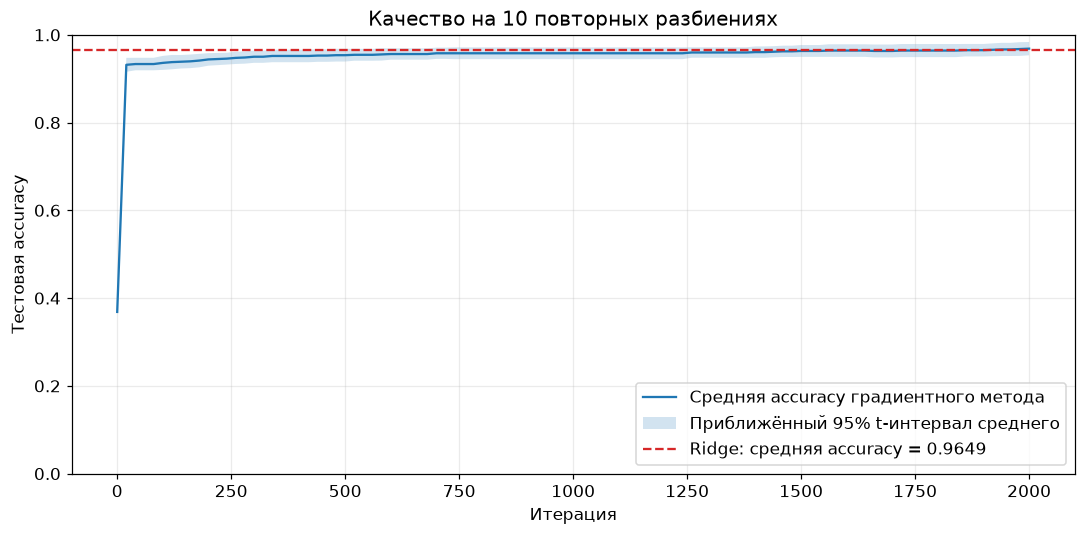

,метод,средняя accuracy в конце,std по разбиениям
0,градиентный,0.968421,0.021166
1,Ridge,0.964912,0.014325


In [9]:
repeat_histories = []
repeat_ridge = []
repeat_rows = []
for seed in range(100, 110):
    fit_idx, test_idx = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=seed)
    fit_X, test_X, _, _ = standardize(X[fit_idx], X[test_idx])
    fitted, history = gd_fit(fit_X, y[fit_idx], **params, X_test=test_X, y_test=y[test_idx])
    repeat_histories.append(history['test_accuracy'].to_numpy())
    ridge_score = accuracy_score(y[test_idx], predict(test_X, ridge_fit(fit_X, y[fit_idx], float(best_ridge['l2']))))
    repeat_ridge.append(ridge_score)
    repeat_rows.append(history.assign(seed=seed, ridge_accuracy=ridge_score))
repeat_scores = np.vstack(repeat_histories)
iterations = history['iteration'].to_numpy()
mean_accuracy = repeat_scores.mean(axis=0)
half_width = t.ppf(0.975, 9) * repeat_scores.std(axis=0, ddof=1) / np.sqrt(10)
lower = np.clip(mean_accuracy - half_width, 0, 1)
upper = np.clip(mean_accuracy + half_width, 0, 1)
ridge_mean = float(np.mean(repeat_ridge))
pd.concat(repeat_rows, ignore_index=True).to_csv(ROOT / 'results/repeated_splits.csv', index=False)
curve = pd.DataFrame({'iteration': iterations, 'mean_accuracy': mean_accuracy,
                      'lower': lower, 'upper': upper})
curve.to_csv(ROOT / 'results/accuracy_curve.csv', index=False)
fig, ax = plt.subplots()
ax.plot(iterations, mean_accuracy, label='Средняя accuracy градиентного метода')
ax.fill_between(iterations, lower, upper, alpha=0.2, label='Приближённый 95% t-интервал среднего')
ax.axhline(ridge_mean, color='tab:red', linestyle='--', label=f'Ridge: средняя accuracy = {ridge_mean:.4f}')
ax.set(xlabel='Итерация', ylabel='Тестовая accuracy', ylim=(0, 1), title='Качество на 10 повторных разбиениях')
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(ROOT / 'figures/test_accuracy.png', dpi=170)
plt.show()
display(pd.DataFrame({'метод': ['градиентный', 'Ridge'],
                      'средняя accuracy в конце': [mean_accuracy[-1], ridge_mean],
                      'std по разбиениям': [repeat_scores[:, -1].std(ddof=1), np.std(repeat_ridge, ddof=1)]}))

## 5. Пути коэффициентов при регуляризации

Используются все 30 признаков и одна тренировочная стандартизация. Свободный член не входит в графики и штрафы. Риск фиксирован по CV. Перебираем 15 логарифмических значений от $10^{-5}$ до $10^1$; второй коэффициент регуляризации равен нулю.

### Численный способ для путей

В первом расчёте субградиентный шаг давал колебания при сильной L1: для $\lambda_1=10$ цель была около 1.0104 вместо известного минимума 0.66086. Поэтому **только для путей коэффициентов** применяется проксимальный градиентный шаг к той же функции $J$. Основной классификатор, CV и кривые обучения сохраняют субградиент $\operatorname{sign}(w)$ из раздела 2. Это исправление способа вычисления графиков относительно первоначального плана.

Обозначим гладкую часть $F=R+\lambda_2\|w\|^2/2$. После $u=\theta-\eta\nabla F(\theta)$ для весов выполняется мягкое пороговое преобразование:

$$w_j^{\mathrm{new}}=\operatorname{sign}(u_j)\max(|u_j|-\eta\lambda_1,0).$$

Свободный член остаётся $b^{\mathrm{new}}=u_b$. Преобразование точно минимизирует сумму квадратичного приближения гладкой части и L1-штрафа. При $\lambda_1=0$ оно сводится к обычному градиентному шагу. В этом эксперименте могут получаться точные нулевые веса благодаря пороговому преобразованию; такое свойство не приписывается основному субградиентному методу.

Для ускорения используется экстраполяция: $q_0=1$, $q_{k+1}=(1+\sqrt{1+4q_k^2})/2$, $z_{k+1}=\theta_{k+1}+((q_k-1)/q_{k+1})(\theta_{k+1}-\theta_k)$. Градиент вычисляется в $z_k$. При росте цели экстраполяция сбрасывается и шаг повторяется из текущих коэффициентов.

Начальная скорость $0.95/L$, где $L=\lambda_{\max}(A^TA/n)/4+\lambda_2$ для логистического риска, $L=2\lambda_{\max}(A^TA/n)+\lambda_2$ для квадратичного hinge. Проверка квадратичной верхней оценки гладкой части уменьшает шаг вдвое при необходимости.

Каждые 1000 итераций вычисляется проксимальное градиентное отображение

$$G_\eta(\theta)=\frac{\theta-\mathrm{prox}_{\eta\lambda_1}(\theta-\eta\nabla F(\theta))}{\eta}.$$

Обучение завершается после как минимум 2000 итераций, если $\|G_\eta\|_2<10^{-6}$, изменение цели меньше $10^{-6}\max(1,|J_{\mathrm{prev}}|)$, а относительное изменение коэффициентов меньше 0.005. Предел 200000 итераций. Невыполненный критерий отмечается в таблице и на графике.

### Контроль сильной L1

При $w=0$ оптимальный свободный член $b=\log(n_+/n_-)$, здесь $\log(170/285)$. Если $\lambda_1\ge\|\nabla_wR(0,b)\|_\infty$, условие оптимальности L1 выполнено, поэтому нулевые веса дают глобальный минимум выпуклой цели. Сравниваем рассчитанную цель с этим минимумом для всех подходящих значений сетки.

In [10]:
def regularized_path_fit(X, y, loss, l1, l2, n_iter=200000):
    A = np.column_stack([X, np.ones(len(X))])
    spectral = np.linalg.eigvalsh(A.T @ A / len(X))[-1]
    factor = {'logistic': 0.25, 'squared_hinge': 2, 'exponential': 1}[loss]
    step = 0.95 / (factor * spectral + l2)
    theta = np.zeros(X.shape[1] + 1)
    z = theta.copy()
    momentum = 1.0
    records = []
    previous_record = theta.copy()
    previous_value = objective_gradient(X, y, theta, loss, l1, l2)[0]
    current_value = previous_value
    for iteration in range(n_iter + 1):
        if iteration % 1000 == 0 or iteration == n_iter:
            smooth_value, smooth_gradient = objective_gradient(X, y, theta, loss, 0, l2)
            mapped = theta - step * smooth_gradient
            mapped[:-1] = np.sign(mapped[:-1]) * np.maximum(np.abs(mapped[:-1]) - step * l1, 0)
            stationarity = np.linalg.norm(theta - mapped) / step
            risk = loss_and_derivative(y * (X @ theta[:-1] + theta[-1]), loss)[0].mean()
            objective_change = abs(current_value - previous_value) / max(1, abs(previous_value))
            coefficient_change = np.linalg.norm(theta - previous_record) / max(1, np.linalg.norm(previous_record))
            stable = iteration >= 2000 and stationarity < 1e-6 and objective_change < 1e-6 and coefficient_change < 5e-3
            records.append({'iteration': iteration, 'risk': risk, 'objective': current_value,
                            'stationarity': stationarity, 'objective_change': objective_change,
                            'coefficient_change': coefficient_change, 'stable': stable})
            if stable:
                break
            previous_record = theta.copy()
            previous_value = current_value
        if iteration == n_iter:
            break
        for attempt in range(2):
            smooth_value, gradient = objective_gradient(X, y, z, loss, 0, l2)
            while True:
                candidate = z - step * gradient
                candidate[:-1] = np.sign(candidate[:-1]) * np.maximum(np.abs(candidate[:-1]) - step * l1, 0)
                candidate_smooth = objective_gradient(X, y, candidate, loss, 0, l2)[0]
                delta = candidate - z
                bound = smooth_value + gradient @ delta + (delta @ delta) / (2 * step)
                if np.isfinite(candidate_smooth) and candidate_smooth <= bound + 1e-12:
                    break
                step *= 0.5
            candidate_value = candidate_smooth + l1 * np.abs(candidate[:-1]).sum()
            if candidate_value <= current_value + 1e-12 or attempt == 1:
                break
            z = theta.copy()
            momentum = 1.0
        next_momentum = (1 + np.sqrt(1 + 4 * momentum ** 2)) / 2
        z = candidate + (momentum - 1) / next_momentum * (candidate - theta)
        theta = candidate
        momentum = next_momentum
        current_value = float(candidate_value)
    return theta, pd.DataFrame(records)

import numpy as np

def check_paths():
    rng = np.random.default_rng(38)
    X = rng.normal(size=(80, 5))
    y = np.r_[np.ones(30), -np.ones(50)]
    b = np.log(30 / 50)
    theta_star = np.r_[np.zeros(5), b]
    l1 = 2.0
    value_star = objective_gradient(X, y, theta_star, 'logistic', l1, 0)[0]
    theta, h = regularized_path_fit(X, y, 'logistic', l1, 0, 20000)
    value = objective_gradient(X, y, theta, 'logistic', l1, 0)[0]
    assert abs(value - value_star) < 1e-6, (value, value_star)
    assert np.max(np.abs(theta[:-1])) < 1e-8
    assert abs(theta[-1] - b) < 1e-4
    assert h['stationarity'].iloc[-1] < 1e-5
    for loss in ['logistic', 'squared_hinge']:
        theta, h = regularized_path_fit(X, y, loss, 0, 0.1, 20000)
        _, gradient = objective_gradient(X, y, theta, loss, 0, 0.1)
        assert np.linalg.norm(gradient) < 1e-5
    return {'known_l1_optimum_gap': abs(value - value_star), 'checks': 'passed'}


path_verification = check_paths()
display(path_verification)

{'known_l1_optimum_gap': 0.0, 'checks': 'passed'}

In [11]:
lambda_grid = np.logspace(-5, 1, 15)
path_rows = []
path_histories = []
paths = {}
zero_theta = np.r_[np.zeros(X_train.shape[1]), np.log((y_train == 1).sum() / (y_train == -1).sum())]
zero_risk, zero_gradient = objective_gradient(X_train, y_train, zero_theta, params['loss'], 0, 0)
zero_threshold = np.max(np.abs(zero_gradient[:-1]))
for kind in ['L1', 'L2']:
    coefficients = []
    for penalty in lambda_grid:
        l1, l2 = (penalty, 0) if kind == 'L1' else (0, penalty)
        theta, h = regularized_path_fit(X_train, y_train, params['loss'], l1, l2)
        last = h.iloc[-1]
        zero_gap = np.nan
        if kind == 'L1' and params['loss'] == 'logistic' and penalty >= zero_threshold:
            zero_gap = abs(last['objective'] - zero_risk)
            assert zero_gap < 1e-6
            assert np.max(np.abs(theta[:-1])) < 1e-8
        coefficients.append(theta[:-1].copy())
        path_rows.append({'kind': kind, 'lambda': penalty, 'iterations': int(last['iteration']),
                          'objective': last['objective'], 'stationarity': last['stationarity'],
                          'objective_change': last['objective_change'],
                          'coefficient_change': last['coefficient_change'],
                          'stable': bool(last['stable']), 'zero_optimum_gap': zero_gap,
                          'l1_norm': np.abs(theta[:-1]).sum(), 'l2_norm': np.linalg.norm(theta[:-1]),
                          'bias': theta[-1]})
        path_histories.append(h.assign(kind=kind, penalty=penalty))
    paths[kind] = np.vstack(coefficients)
path_diagnostics = pd.DataFrame(path_rows)
path_diagnostics.to_csv(ROOT / 'results/regularization_diagnostics.csv', index=False)
pd.concat(path_histories, ignore_index=True).to_csv(ROOT / 'results/regularization_histories.csv', index=False)
for kind, coefficient_matrix in paths.items():
    pd.DataFrame(coefficient_matrix, index=lambda_grid, columns=feature_names).rename_axis('lambda').to_csv(
        ROOT / f'results/{kind.lower()}_coefficients.csv')
display(path_diagnostics)
print('Стабилизировалось:', int(path_diagnostics['stable'].sum()), 'из', len(path_diagnostics))
print('Контроль сильной L1: порог', zero_threshold, 'минимум', zero_risk)

,kind,lambda,iterations,objective,stationarity,objective_change,coefficient_change,stable,zero_optimum_gap,l1_norm,l2_norm,bias
0,L1,0.000010,43000,0.007625,4.696682e-07,3.145012e-08,4.547634e-04,True,NaN,557.100018,141.495198,4.590944
1,L1,0.000027,21000,0.014976,2.593215e-07,3.813162e-08,4.082677e-03,True,NaN,347.953191,87.437563,3.209907
2,L1,0.000072,7000,0.025068,4.519881e-07,5.141867e-08,4.865483e-03,True,NaN,148.856783,36.648344,0.965571
3,L1,0.000193,6000,0.036608,1.563783e-08,6.779546e-11,1.162896e-04,True,NaN,69.382728,17.480596,1.191373
4,L1,0.000518,3000,0.052075,2.764466e-07,3.539256e-08,4.931651e-03,True,NaN,34.289603,9.758331,0.606918
5,L1,0.001389,4000,0.072777,1.759641e-08,3.149481e-12,1.579855e-05,True,NaN,18.770146,6.777939,0.214648
6,L1,0.003728,3000,0.106429,4.931339e-09,5.003359e-13,8.364159e-06,True,NaN,11.503590,4.506472,-0.325266
7,L1,0.010000,2000,0.160367,1.287711e-09,3.896411e-12,1.938606e-05,True,NaN,6.941193,3.242046,-0.549765
8,L1,0.026827,2000,0.249561,2.301461e-09,1.928457e-13,5.147250e-06,True,NaN,4.268846,2.256054,-0.692997
9,L1,0.071969,2000,0.391193,5.108751e-11,1.665335e-16,1.346540e-07,True,NaN,2.392574,1.424728,-0.670004


Стабилизировалось: 30 из 30
Контроль сильной L1: порог 0.38038825508379726 минимум 0.6608575273573022


На графиках один цвет соответствует одному признаку. Полные английские названия исходного набора сохранены в легенде. Нормы коэффициентов, проксимальная стационарность и изменения цели приведены в таблице выше. Стабилизация по численным критериям не служит доказательством точного решения для всех точек.

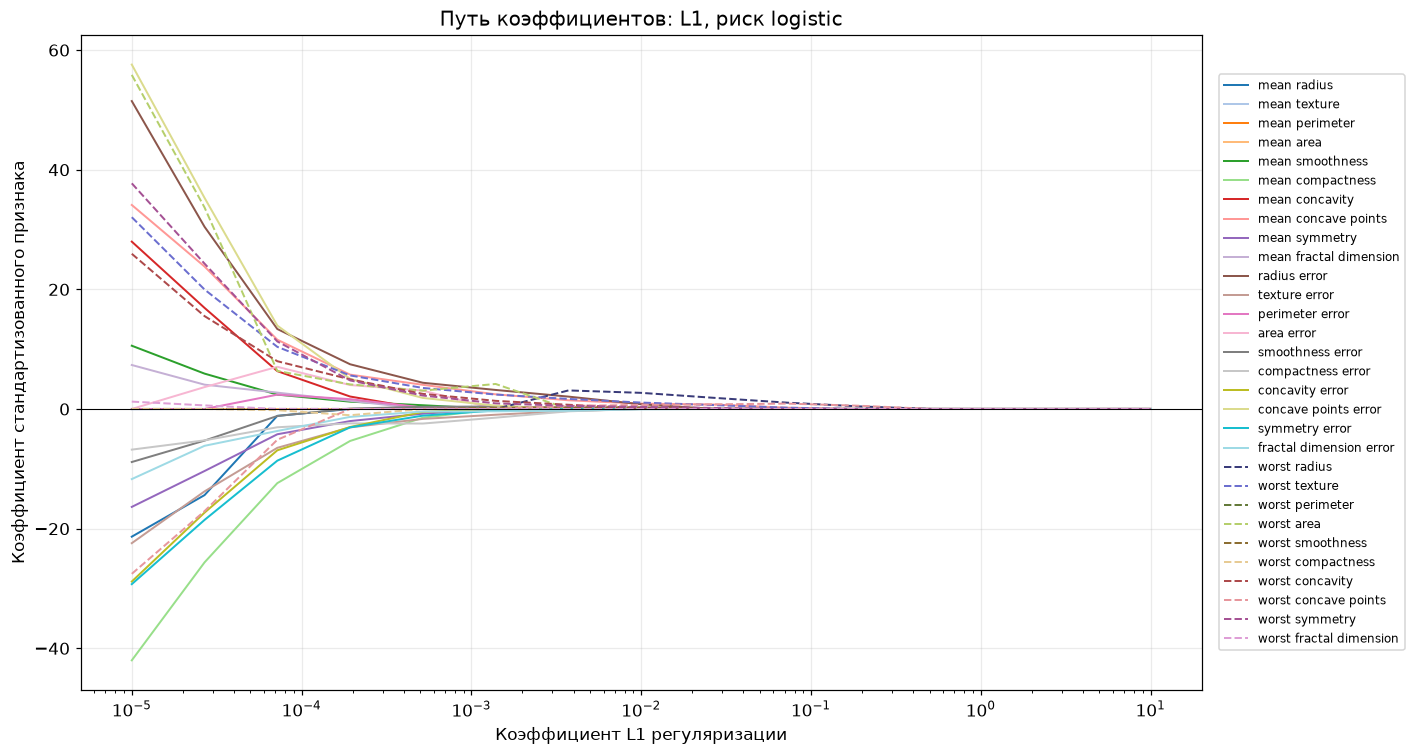

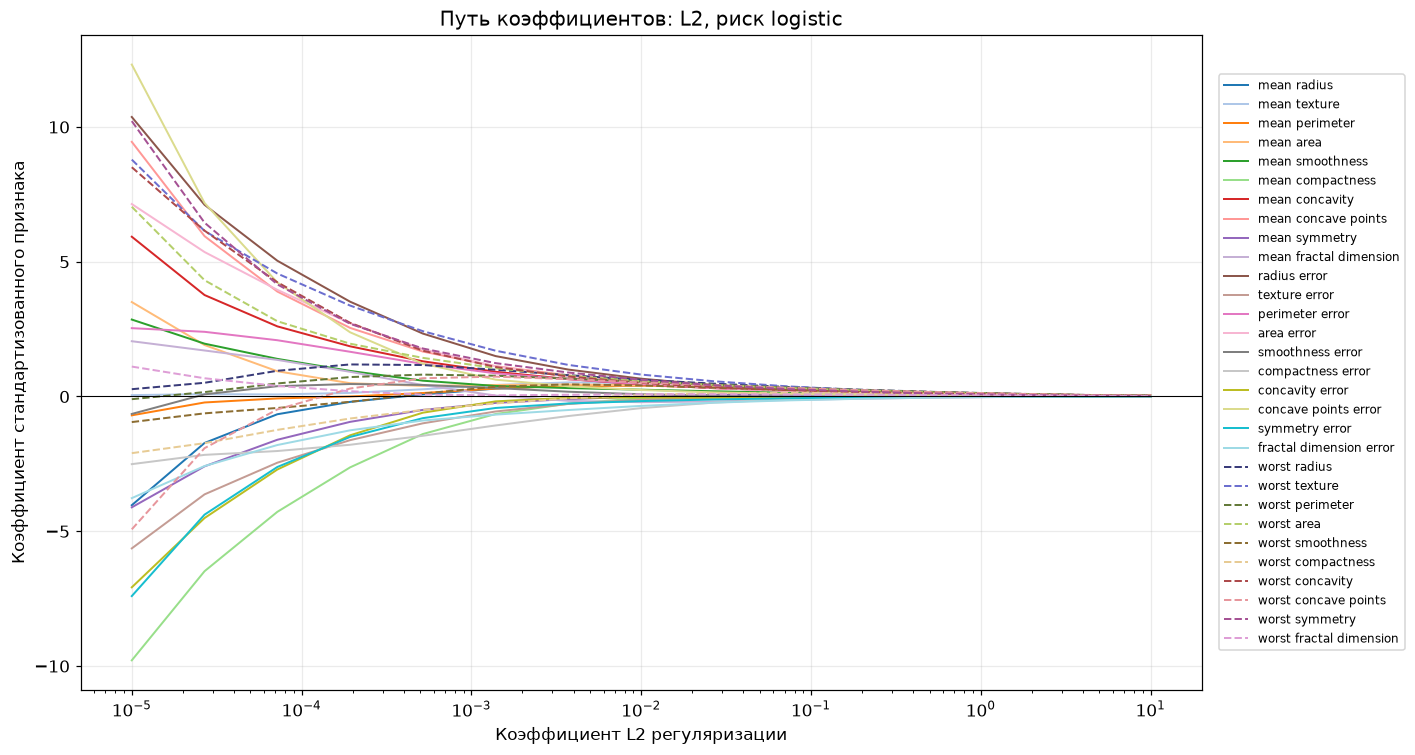

In [12]:
colors = [plt.cm.tab20(i / 19) for i in range(20)] + [plt.cm.tab20b(i / 9) for i in range(10)]
for kind, coefficient_matrix in paths.items():
    fig, ax = plt.subplots(figsize=(13, 7))
    for j, feature in enumerate(feature_names):
        ax.plot(lambda_grid, coefficient_matrix[:, j], color=colors[j],
                linestyle='-' if j < 20 else '--', linewidth=1.3, label=feature)
    bad = path_diagnostics[(path_diagnostics['kind'] == kind) & (~path_diagnostics['stable'])]['lambda']
    for value in bad:
        ax.axvline(value, color='red', alpha=0.25, linestyle=':')
    ax.set_xscale('log')
    ax.axhline(0, color='black', linewidth=0.7)
    ax.set(xlabel=f'Коэффициент {kind} регуляризации', ylabel='Коэффициент стандартизованного признака',
           title=f"Путь коэффициентов: {kind}, риск {params['loss']}")
    ax.legend(loc='center left', bbox_to_anchor=(1.01, 0.5), fontsize=8, ncol=1)
    fig.tight_layout()
    fig.savefig(ROOT / f'figures/{kind.lower()}_path.png', dpi=170)
    plt.show()

## 6. Результаты и выводы

Числа ниже вычислены выполненными ячейками. Качество на финальной тестовой части оценивает две модели после выбора параметров; повторные разбиения описывают обучение при уже фиксированных параметрах.

In [13]:
best_per_loss = gd_cv.loc[gd_cv.groupby('loss', sort=False)['mean_accuracy'].idxmax()]
display(best_per_loss[['loss', 'learning_rate', 'l1', 'l2', 'mean_accuracy']])
ridge_test = float(final_results.loc[0, 'test_accuracy'])
gd_test = float(final_results.loc[1, 'test_accuracy'])
unstable = int((~path_diagnostics['stable']).sum())
lines = [
    f"1. Ridge выбрал λ = {float(best_ridge['l2']):.6g}; средняя CV accuracy {float(best_ridge['mean_accuracy']):.4f}, финальная тестовая accuracy {ridge_test:.4f} ({int(final_results.loc[0, 'correct'])}/114).",
    f"2. Градиентный метод выбрал риск {params['loss']}, η = {params['learning_rate']}, λ₁ = {params['l1']}, λ₂ = {params['l2']}; средняя CV accuracy {float(best_gd['mean_accuracy']):.4f}, финальная тестовая accuracy {gd_test:.4f} ({int(final_results.loc[1, 'correct'])}/114).",
    f"3. Исходный тренировочный риск изменился с {train_history['risk'].iloc[0]:.6f} до {train_history['risk'].iloc[-1]:.6f}. На десяти разбиениях средняя accuracy градиентного метода в конце {mean_accuracy[-1]:.4f}, Ridge {ridge_mean:.4f}. Приближённый интервал среднего в конце [{lower[-1]:.4f}; {upper[-1]:.4f}].",
]
for kind in ['L1', 'L2']:
    part = path_diagnostics[path_diagnostics['kind'] == kind]
    norm = 'l1_norm' if kind == 'L1' else 'l2_norm'
    lines.append(f"{len(lines) + 1}. При увеличении λ для {kind} с 10⁻⁵ до 10 соответствующая норма коэффициентов изменилась с {part[norm].iloc[0]:.5f} до {part[norm].iloc[-1]:.5f}. Отдельные коэффициенты могут меняться немонотонно из-за корреляции признаков; сравниваем общую тенденцию по норме.")
lines.append(f"{len(lines) + 1}. Численная стабилизация подтверждена для {30 - unstable}/30 точек путей по указанным критериям. " +
             ("Для оставшихся точек достигнут предел итераций; их коэффициенты следует считать приближёнными, а влияние слабой регуляризации не отделено полностью от незавершённого обучения." if unstable else "Все точки прошли диагностику проксимальной стационарности, изменения цели и коэффициентов; это не означает точного аналитического решения."))
lines.append(f"{len(lines) + 1}. Разница качества на одной тестовой части и зависимые повторные разбиения не доказывают статистического превосходства метода. Поиск ограничен указанной сеткой и бюджетом 2000 итераций; выбранные параметры лучшие в этом эксперименте.")
conclusions = (chr(10) * 2).join(lines)
display(Markdown(conclusions))
summary = {'seed': SEED, 'ridge_l2': float(best_ridge['l2']), 'gd_params': params,
           'ridge_cv_accuracy': float(best_ridge['mean_accuracy']), 'gd_cv_accuracy': float(best_gd['mean_accuracy']),
           'ridge_test_accuracy': ridge_test, 'gd_test_accuracy': gd_test,
           'repeat_gd_mean': float(mean_accuracy[-1]), 'repeat_ridge_mean': ridge_mean,
           'path_stable_count': 30 - unstable, 'verification': verification, 'path_verification': path_verification}
(ROOT / 'results/summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2))
(ROOT / 'results/conclusions.md').write_text(conclusions + chr(10))
assert len(ridge_cv) == 8 and len(gd_cv) == 45
assert repeat_scores.shape == (10, len(iterations))
assert all(np.isfinite(p).all() for p in paths.values())
assert np.isfinite(train_history.select_dtypes('number').to_numpy()).all()
assert all((ROOT / f'figures/{name}.png').exists() for name in ['train_risk', 'test_accuracy', 'l1_path', 'l2_path'])
print('Все вычисления завершены; результаты и четыре графика сохранены.')

,loss,learning_rate,l1,l2,mean_accuracy
5,logistic,0.005,0.00,0.00,0.978022
25,exponential,0.010,0.00,0.00,0.975824
34,squared_hinge,0.001,0.01,0.01,0.973626


1. Ridge выбрал λ = 0.001; средняя CV accuracy 0.9582, финальная тестовая accuracy 0.9561 (109/114).

2. Градиентный метод выбрал риск logistic, η = 0.005, λ₁ = 0.0, λ₂ = 0.0; средняя CV accuracy 0.9780, финальная тестовая accuracy 0.9825 (112/114).

3. Исходный тренировочный риск изменился с 0.693147 до 0.103852. На десяти разбиениях средняя accuracy градиентного метода в конце 0.9684, Ridge 0.9649. Приближённый интервал среднего в конце [0.9533; 0.9836].

4. При увеличении λ для L1 с 10⁻⁵ до 10 соответствующая норма коэффициентов изменилась с 557.10002 до 0.00000. Отдельные коэффициенты могут меняться немонотонно из-за корреляции признаков; сравниваем общую тенденцию по норме.

5. При увеличении λ для L2 с 10⁻⁵ до 10 соответствующая норма коэффициентов изменилась с 32.97183 до 0.10814. Отдельные коэффициенты могут меняться немонотонно из-за корреляции признаков; сравниваем общую тенденцию по норме.

6. Численная стабилизация подтверждена для 30/30 точек путей по указанным критериям. Все точки прошли диагностику проксимальной стационарности, изменения цели и коэффициентов; это не означает точного аналитического решения.

7. Разница качества на одной тестовой части и зависимые повторные разбиения не доказывают статистического превосходства метода. Поиск ограничен указанной сеткой и бюджетом 2000 итераций; выбранные параметры лучшие в этом эксперименте.

Все вычисления завершены; результаты и четыре графика сохранены.


## 7. Соответствие условию

| Требование | Раздел |
|:---|:---|
| Бинарный набор, числовые признаки, нормализация, train/test, метрика | 1 |
| Матричная регрессия с Ridge и классификация по меткам ±1 | 2, 3 |
| Собственный градиентный метод, три риска через отступ, аналитические градиенты, Elastic Net, скорость | 2 |
| Подбор гиперпараметров для обоих алгоритмов | 3 |
| Сглаженный тренировочный эмпирический риск | 4 |
| Тестовая метрика на разных разбиениях, доверительная полоса, линия Ridge | 4 |
| Пути коэффициентов по L1 при L2 = 0 и по L2 при L1 = 0 | 5 |
| Выводы по фактически рассчитанным результатам | 6 |

Подробные таблицы находятся в `results/`, изображения в `figures/`. Ноутбук выполняется сверху вниз; HTML-копия предназначена для просмотра без Jupyter.